# 1. A first look at maximum likelihood

Portfolio exercises [MLE 1.1–1.3.5]. Section 1.1 uses the five-coin grid;
Sections 1.2–1.3 use the unrestricted Bernoulli MLE $\hat\theta=k/m$.
Every identity used below is checked numerically next to it.

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar
from scipy.stats import binom, norm

rng = np.random.default_rng(2026)
plt.rcParams.update({"figure.figsize": (7, 4.2), "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 10})

## 1.1 Five coins [MLE 1.3.2–1.3.3]

### Task

Five coins with $\theta_i=i/4$, observation $y=(1,0,0)$.

p(y|theta_i) = [0.       0.140625 0.125    0.046875 0.      ]
argmax = 0.25  (k/m = 0.3333333333333333 )


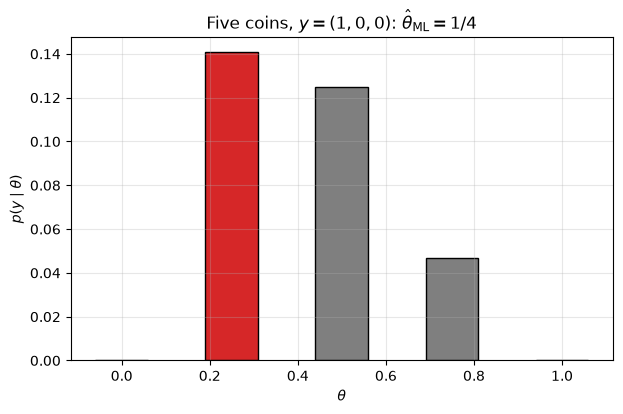

In [16]:
theta_c = np.array([0.0, 0.25, 0.50, 0.75, 1.0])
y = np.array([1, 0, 0])
m = len(y)
k = int(y.sum())
lik = theta_c**k * (1 - theta_c)**(m - k)
i_ml = int(np.argmax(lik))
print("p(y|theta_i) =", lik)
print("argmax =", theta_c[i_ml], " (k/m =", k / m, ")")
# Exact values from [MLE 1.3.2]: 0, 9/64, 8/64, 3/64, 0.
assert np.allclose(lik, [0, 9/64, 8/64, 3/64, 0])
assert theta_c[i_ml] == 0.25

fig, ax = plt.subplots()
cols = ["tab:gray"] * len(theta_c)
cols[i_ml] = "tab:red"
ax.bar(theta_c, lik, width=0.12, color=cols, edgecolor="black")
ax.set_xlabel(r"$\theta$")
ax.set_ylabel(r"$p(y\mid\theta)$")
ax.set_title(r"Five coins, $y=(1,0,0)$: $\hat\theta_{\rm ML}=1/4$")
plt.show()

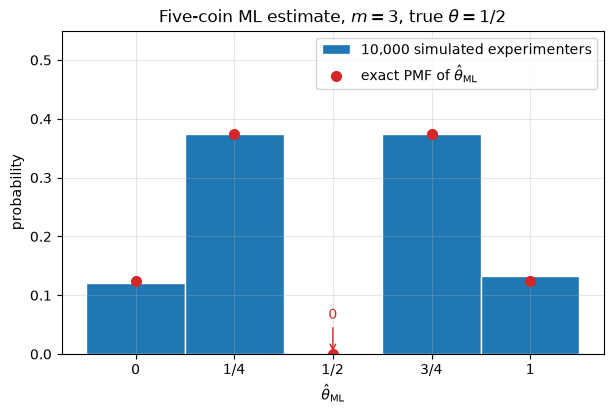

empirical PMF: [0.12   0.3735 0.     0.3746 0.1319]
exact PMF    : [0.125 0.375 0.    0.375 0.125]


In [17]:
def ml_coin(counts, m):
    """Index of the ML coin on the five-point grid for each count k."""
    counts = np.asarray(counts)
    L = theta_c[None, :]**counts[:, None] * (1 - theta_c)[None, :]**(m - counts[:, None])
    return np.argmax(L, axis=1)

N = 10_000
m_sim = 3
k_sim = rng.binomial(m_sim, 0.5, size=N)
est = theta_c[ml_coin(k_sim, m_sim)]

# Exact PMF: enumerate k and apply the same argmax rule.
k_all = np.arange(m_sim + 1)
idx_all = ml_coin(k_all, m_sim)
exact_pmf = np.array([binom.pmf(k_all[idx_all == j], m_sim, 0.5).sum()
                      for j in range(len(theta_c))])

edges = np.concatenate(([-0.125], (theta_c[:-1] + theta_c[1:]) / 2, [1.125]))
fig, ax = plt.subplots()
ax.hist(est, bins=edges, weights=np.ones(N) / N, color="tab:blue",
        edgecolor="white", label="10,000 simulated experimenters")
ax.plot(theta_c, exact_pmf, "o", ms=7, color="tab:red",
        label=r"exact PMF of $\hat\theta_{\rm ML}$")
ax.annotate("0", xy=(0.5, 0), xytext=(0.5, 0.06), ha="center",
            color="tab:red", arrowprops=dict(arrowstyle="->", color="tab:red"))
ax.set_xticks(theta_c)
ax.set_xticklabels(["$0$", "$1/4$", "$1/2$", "$3/4$", "$1$"])
ax.set_xlabel(r"$\hat\theta_{\rm ML}$")
ax.set_ylabel("probability")
ax.set_title(r"Five-coin ML estimate, $m=3$, true $\theta=1/2$")
ax.set_ylim(0, 0.55)
ax.legend(loc="upper right")
plt.show()

emp = np.array([np.mean(est == c) for c in theta_c])
print("empirical PMF:", np.round(emp, 4))
print("exact PMF    :", np.round(exact_pmf, 4))
assert np.allclose(emp, exact_pmf, atol=0.015)
assert exact_pmf[2] == 0.0
assert not np.any(est == 0.5)

### Explore: $m=10,30,100$ tosses, keeping the five candidate coins

The estimator stays restricted to $\{0,\tfrac14,\tfrac12,\tfrac34,1\}$:
for each data set the ML coin maximises $\theta^k(1-\theta)^{m-k}$. The
exact PMF sums the binomial probabilities over the counts $k$ that select
each coin.

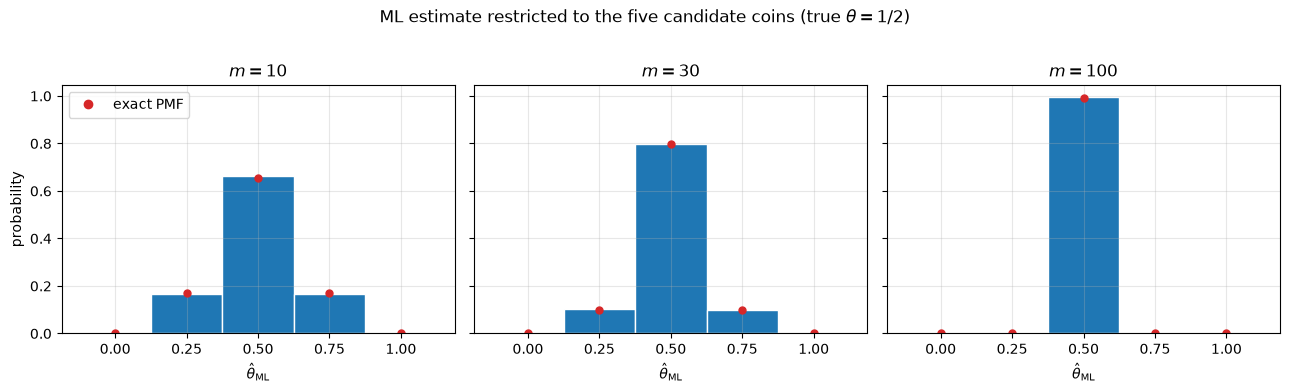

In [18]:
ms = [10, 30, 100]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, mm in zip(axes, ms):
    kk = rng.binomial(mm, 0.5, size=N)
    est = theta_c[ml_coin(kk, mm)]
    k_all = np.arange(mm + 1)
    idx_all = ml_coin(k_all, mm)
    pmf = np.array([binom.pmf(k_all[idx_all == j], mm, 0.5).sum()
                    for j in range(len(theta_c))])
    ax.hist(est, bins=edges, weights=np.ones(N) / N,
            color="tab:blue", edgecolor="white")
    ax.plot(theta_c, pmf, "o", ms=5, color="tab:red")
    emp = np.array([np.mean(est == c) for c in theta_c])
    assert np.allclose(emp, pmf, atol=0.02)
    ax.set_xticks(theta_c)
    ax.set_title(f"$m={mm}$")
    ax.set_xlabel(r"$\hat\theta_{\rm ML}$")
    if ax is axes[0]:
        ax.set_ylabel("probability")
        ax.plot([], [], "o", color="tab:red", label="exact PMF")
        ax.legend(loc="upper left")
fig.suptitle("ML estimate restricted to the five candidate coins "
             r"(true $\theta=1/2$)", y=1.02)
plt.tight_layout()
plt.show()

### Explain

The estimator is a random variable because $\hat\theta_{\rm ML}=T(Y)$ is a function of the random sample: a different experiment gives a different $k$, hence a different selected coin. As the histogram shows, with the true coin at $1/2$ the estimate is $1/2$ increasingly often as $m$ grows, probability $0$ for $m=3$ (no count $k$ selects that coin), then $0.66$, $0.80$, $0.99$ for $m=10,30,100$, because the likelihood concentrates around $k/m\approx1/2$.

## 1.2 The Bernoulli likelihood [MLE 1.1, 1.3.4]

### Task

The parameter is unrestricted on $(0,1)$, so the ML value is $k/m$.

m = 10  k = 3  k/m = 0.3
minimize_scalar theta_hat = 0.29999962826327425
grid argmax theta_hat     = 0.300154072036018


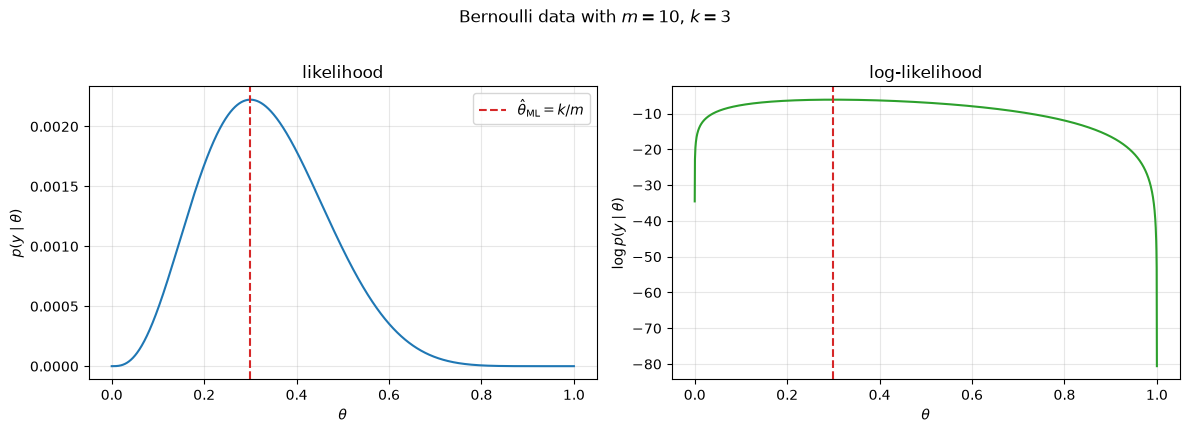

In [19]:
y = np.array([1, 0, 0, 1, 0, 0, 0, 1, 0, 0])
m = len(y)
k = int(y.sum())
print("m =", m, " k =", k, " k/m =", k / m)

th = np.linspace(1e-5, 1 - 1e-5, 2000)
lik = th**k * (1 - th)**(m - k)
loglik = k * np.log(th) + (m - k) * np.log(1 - th)

res = minimize_scalar(lambda t: -(k * np.log(t) + (m - k) * np.log(1 - t)),
                      bounds=(1e-8, 1 - 1e-8), method="bounded")
i_grid = int(np.argmax(loglik))
print("minimize_scalar theta_hat =", res.x)
print("grid argmax theta_hat     =", th[i_grid])
assert np.allclose(res.x, k / m, atol=1e-5)
assert np.allclose(th[i_grid], k / m, atol=1e-3)
assert np.allclose(loglik.max(), np.log(lik.max()))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(th, lik, color="tab:blue")
axes[0].axvline(k / m, color="tab:red", ls="--",
                label=r"$\hat\theta_{\rm ML}=k/m$")
axes[0].set_xlabel(r"$\theta$"); axes[0].set_ylabel(r"$p(y\mid\theta)$")
axes[0].set_title("likelihood")
axes[0].legend()
axes[1].plot(th, loglik, color="tab:green")
axes[1].axvline(k / m, color="tab:red", ls="--")
axes[1].set_xlabel(r"$\theta$"); axes[1].set_ylabel(r"$\log p(y\mid\theta)$")
axes[1].set_title("log-likelihood")
fig.suptitle(r"Bernoulli data with $m=10$, $k=3$", y=1.02)
plt.tight_layout(); plt.show()

### Explore: keep $k/m=0.3$ and increase $m$

The raw likelihood underflows for large $m$; the normalised
log-likelihood $(1/m)\log p(y\mid\theta)$ does not.

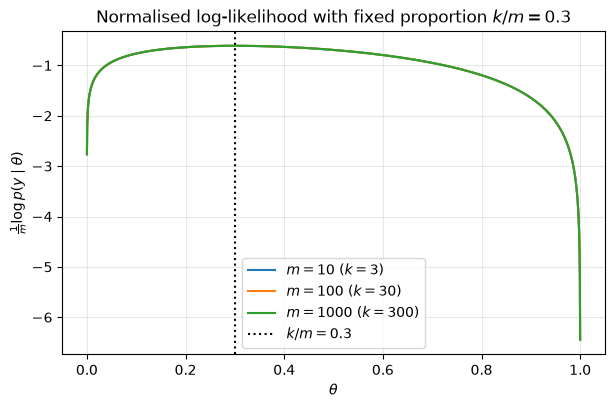

m=1000: max p = 5.070e-266,  max log p = -610.9
m=2000: max p = 0.000e+00,  max log p = -1221.7
curvature at theta=0.3002: -4.7585 (Fisher: -4.7619)


In [20]:
th = np.linspace(1e-4, 1 - 1e-4, 2000)
fig, ax = plt.subplots()
for mm in [10, 100, 1000]:
    kk = int(round(0.3 * mm))
    ll = kk * np.log(th) + (mm - kk) * np.log(1 - th)
    ax.plot(th, ll / mm, label=f"$m={mm}$ ($k={kk}$)")
    assert np.all(np.diff(ll, 2) < 0)                 # strict concavity
    assert abs(th[np.argmax(ll)] - 0.3) < 1e-3        # same maximiser
ax.axvline(0.3, color="black", ls=":", label=r"$k/m=0.3$")
ax.set_xlabel(r"$\theta$"); ax.set_ylabel(r"$\frac{1}{m}\log p(y\mid\theta)$")
ax.set_title("Normalised log-likelihood with fixed proportion $k/m=0.3$")
ax.legend(); plt.show()

# Raw likelihood underflows; log-likelihood stays finite.
for mm in [1000, 2000]:
    kk = int(round(0.3 * mm))
    raw = 0.3**kk * 0.7**(mm - kk)
    ll0 = kk * np.log(0.3) + (mm - kk) * np.log(0.7)
    print(f"m={mm:4d}: max p = {raw:.3e},  max log p = {ll0:.1f}")
assert 0.3**300 * 0.7**700 > 0
assert 0.3**600 * 0.7**1400 == 0.0

# Curvature at the peak is minus the Fisher information per observation.
mm, kk = 1000, 300
ll = kk * np.log(th) + (mm - kk) * np.log(1 - th)
h = th[1] - th[0]
j = int(np.argmin(abs(th - 0.3)))
curv = (ll[j + 1] - 2 * ll[j] + ll[j - 1]) / h**2 / mm
exact = -0.3 / th[j]**2 - 0.7 / (1 - th[j])**2
assert np.isclose(curv, exact, rtol=1e-5)
assert np.isclose(exact, -1 / (0.3 * 0.7), rtol=1e-3)
print(f"curvature at theta={th[j]:.4f}: {curv:.4f} (Fisher: {-1/(0.3*0.7):.4f})")

### Explain

$\log$ is strictly increasing, so
$\log p(y\mid\theta_1)>\log p(y\mid\theta_2)\iff p(y\mid\theta_1)>p(y\mid\theta_2)$:
the maximiser is the same. The likelihood is a product of $m$ factors in
$(0,1)$, so it decays exponentially: at $m=1000$ its maximum is about
$10^{-266}$ and by $m\approx1220$ it underflows to $0$. The log-likelihood
is a sum of moderate numbers and stays finite (about $-1222$ at $m=2000$).
On $0<\theta<1$ it is strictly concave,
$\frac{d^2}{d\theta^2}\log p=-k/\theta^2-(m-k)/(1-\theta)^2<0$, so the
stationary point $k/m$ is the unique maximiser.

## 1.3 Bias and variance of $\hat\theta_{\rm ML}$ [MLE 1.3.5, 1.3.10]

### Task

Here $\hat\theta_{\rm ML}=k/m$ is unrestricted; its exact law is the scaled
binomial of [MLE 1.3.5], which lets us overlay the exact PMF and a normal
approximation.

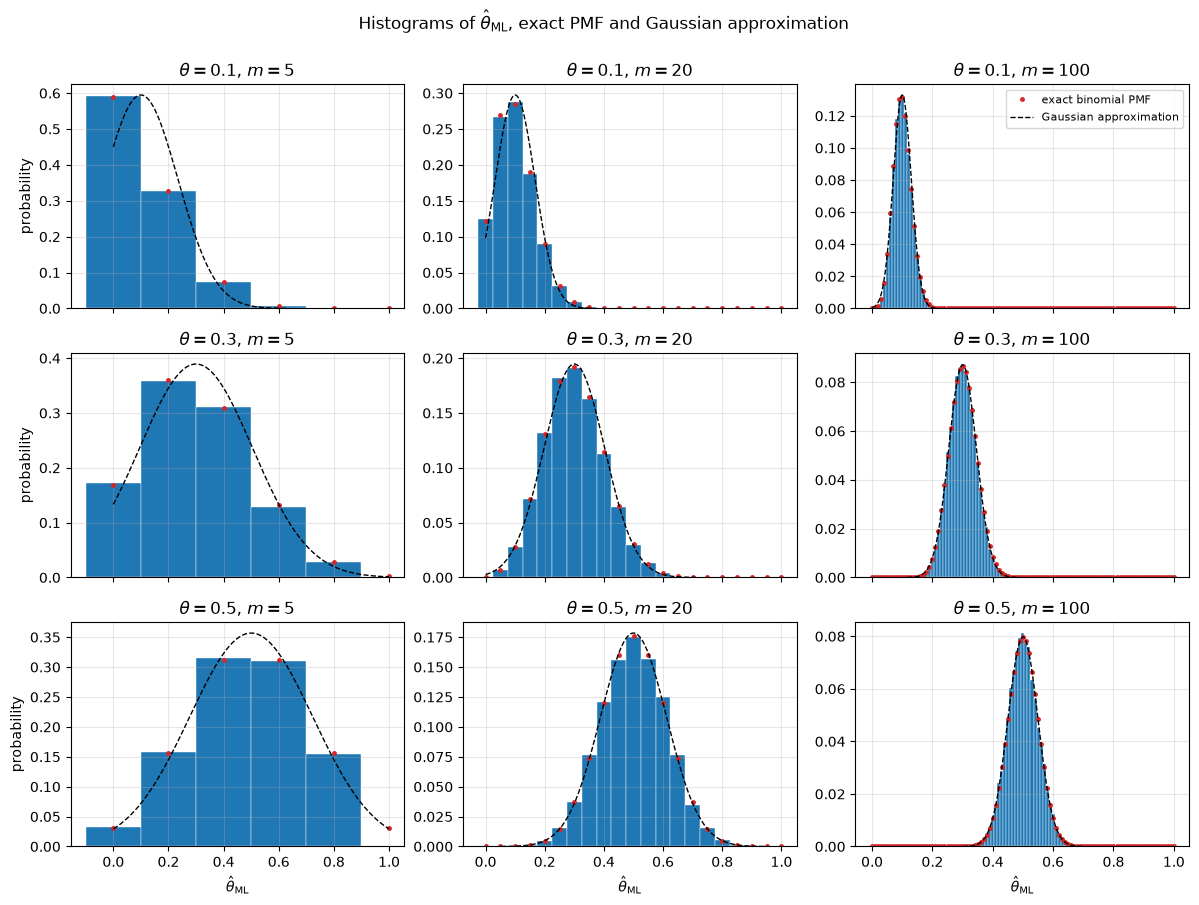

 theta    m     E emp   E exact    Var emp  Var exact    skew
   0.1    5    0.0996    0.1000    0.01791    0.01800   1.193
   0.1   20    0.0999    0.1000    0.00453    0.00450   0.596
   0.1  100    0.0998    0.1000    0.00089    0.00090   0.267
   0.3    5    0.2983    0.3000    0.04199    0.04200   0.390
   0.3   20    0.2991    0.3000    0.01046    0.01050   0.195
   0.3  100    0.3003    0.3000    0.00208    0.00210   0.087
   0.5    5    0.4979    0.5000    0.05003    0.05000   0.000
   0.5   20    0.5002    0.5000    0.01266    0.01250   0.000
   0.5  100    0.4999    0.5000    0.00251    0.00250   0.000


In [21]:
thetas = [0.1, 0.3, 0.5]
ms = [5, 20, 100]
Nsim = 30_000
fig, axes = plt.subplots(len(thetas), len(ms), figsize=(12, 9), sharex="col")
rows = []
for i, theta in enumerate(thetas):
    for j, mm in enumerate(ms):
        kk = rng.binomial(mm, theta, size=Nsim)
        est = kk / mm
        mean_e, var_e = est.mean(), est.var(ddof=0)
        mean_t, var_t = theta, theta * (1 - theta) / mm
        skew = (1 - 2 * theta) / np.sqrt(mm * theta * (1 - theta))
        rows.append((theta, mm, mean_e, var_e, mean_t, var_t, skew))
        ax = axes[i, j]
        edges = (np.arange(mm + 1) - 0.5) / mm
        ax.hist(est, bins=edges, weights=np.ones(Nsim) / Nsim,
                color="tab:blue", edgecolor="white", linewidth=0.3)
        grid = np.arange(mm + 1) / mm
        pmf = binom.pmf(np.arange(mm + 1), mm, theta)
        ax.plot(grid, pmf, "o", ms=2.5, color="tab:red",
                label="exact binomial PMF")
        sd = np.sqrt(theta * (1 - theta) / mm)
        xx = np.linspace(max(0, theta - 4 * sd), min(1, theta + 4 * sd), 300)
        ax.plot(xx, norm.pdf(xx, theta, sd) / mm, "--", color="black",
                lw=1, label="Gaussian approximation")
        ax.set_title(rf"$\theta={theta}$, $m={mm}$")
        if j == 0:
            ax.set_ylabel("probability")
        if i == len(thetas) - 1:
            ax.set_xlabel(r"$\hat\theta_{\rm ML}$")
        if i == 0 and j == len(ms) - 1:
            ax.legend(loc="upper right", fontsize=8)
fig.suptitle(r"Histograms of $\hat\theta_{\rm ML}$, exact PMF and Gaussian approximation",
             y=1.00)
plt.tight_layout(); plt.show()

print(f"{'theta':>6} {'m':>4} {'E emp':>9} {'E exact':>9} "
      f"{'Var emp':>10} {'Var exact':>10} {'skew':>7}")
for theta, mm, me, ve, mt, vt, sk in rows:
    print(f"{theta:6.1f} {mm:4d} {me:9.4f} {mt:9.4f} "
          f"{ve:10.5f} {vt:10.5f} {sk:7.3f}")
    assert np.allclose(me, mt, atol=0.01)
    assert np.allclose(ve, vt, rtol=0.05, atol=1e-4)

# Exact identity for the skewness quoted in the Explain.
kk = np.arange(ms[-1] + 1)
pmf = binom.pmf(kk, ms[-1], thetas[0])
mu = np.sum(pmf * kk / ms[-1])
sd = np.sqrt(np.sum(pmf * (kk / ms[-1] - mu)**2))
skew_direct = np.sum(pmf * ((kk / ms[-1] - mu) / sd)**3)
assert np.isclose(skew_direct,
                  (1 - 2 * thetas[0]) / np.sqrt(ms[-1] * thetas[0] * (1 - thetas[0])))

### Explain

The estimator is least precise at $\theta=1/2$: its variance $\theta(1-\theta)/m$ is maximal there and the binomial PMF is widest. For $\theta$ near $0$ or $1$ the data are almost deterministic and the estimate is much more concentrated. At $m=20$ the Gaussian overlay is already accurate at $\theta=1/2$ (skewness $0$), but at $\theta=0.1$ the law is still markedly skewed and only looks symmetric by $m=100$.